<a href="https://colab.research.google.com/github/AhmadSyahreza/Data-Analyst/blob/main/HW6_Ahmad_Syahreza_Nouval_Siregar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW6 - Visualisasi data

**Dataset:** (`BankChurners.csv`) dari kaggle


---

Disini saya langsung menggabungkan soal soalnya dalam kelia grafik yang dibuat, sehingga isi grafiknya berbeda beda

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from pathlib import Path

Saving BankChurners.csv to BankChurners (2).csv


### Unggah data set, ini berdasarkan komputer masing masing ya. dibawahnya baru bisa pakai yang import dari drive saya

In [ ]:
#sns.set_theme(style="whitegrid")
#plt.rcParams["figure.figsize"] = (9, 5)

#uploaded = files.upload()
#csv_name = next((name for name in uploaded if name.lower().endswith(".csv")), None)
#if csv_name is None:
#    raise FileNotFoundError("Upload filenya dulu, ini nyari di komputer kita masing masing")

### Ini yang pakai drive

In [14]:
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/DigitalSkola'

df = pd.read_csv(f'{BASE}/BankChurners.csv')

Mounted at /content/drive


### ini kalau pakai yg pertama

In [ ]:
#df = pd.read_csv(csv_name)

### Membersihkan data atau Data Cleaning

In [11]:
nb_cols = [c for c in df.columns if c.startswith("Naive_Bayes_Classifier")]
df = df.drop(columns=["CLIENTNUM"] + nb_cols, errors="ignore")

### Menampilkan ukuran data

In [12]:
print(f"Data shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Data shape: 10,127 rows × 20 columns


,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


### Mengecek nilai yang kosong

In [13]:
print("\\nMissing values:")
display(df.isna().sum().to_frame("missing_values").query("missing_values > 0"))

\nMissing values:


,missing_values


## 5 Visualisasi

Each requested column is represented by exactly one visualization below.

### Pie Chart

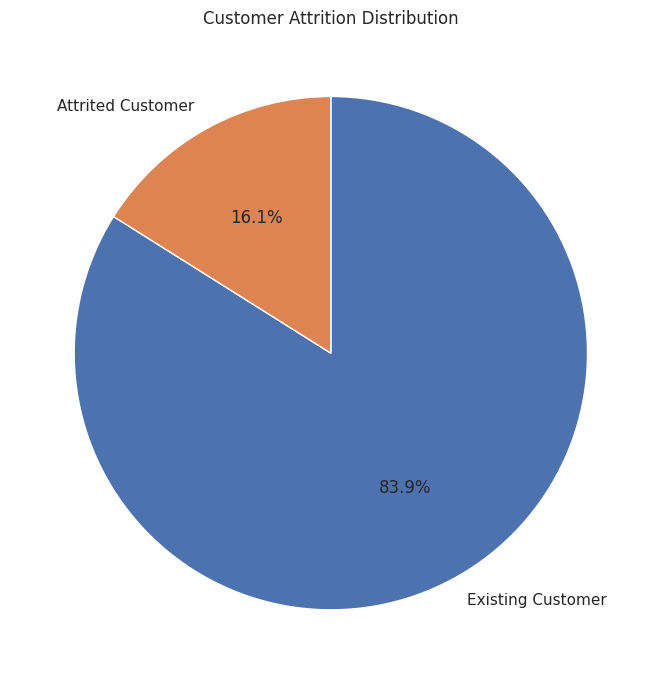

Insight: 8,500 customers (83.9%) Pelanggan yang masih aktif, while 1,627 (16.1%) are attrited. Dataset nya ga seimbang Datasetnya ga seimbang ke arah yang masih aktif


In [15]:
attrition_counts = df["Attrition_Flag"].value_counts() #sesuai fungsi 'counts' ini menghitung jumlah datanya

#Bikin grafik lingkarannya (Pie Chart)
plt.figure(figsize=(7, 7))
plt.pie(attrition_counts.values, labels=attrition_counts.index, autopct="%1.1f%%",
        startangle=90, counterclock=False)
plt.title("Customer Attrition Distribution")
plt.tight_layout()
plt.show()


total = attrition_counts.sum() #Jumlah total datanya yang tdi dihitung

attrited = attrition_counts.get("Attrited Customer", 0) #Data keluar/berhenti
existing = attrition_counts.get("Existing Customer", 0) #Data yang masih aktif

print(f"Insight: {existing:,} customers ({existing/total:.1%}) Pelanggan yang masih aktif, "
      f"while {attrited:,} ({attrited/total:.1%}) are attrited. Dataset nya ga seimbang "
      "Datasetnya ga seimbang ke arah yang masih aktif")

### Histogram

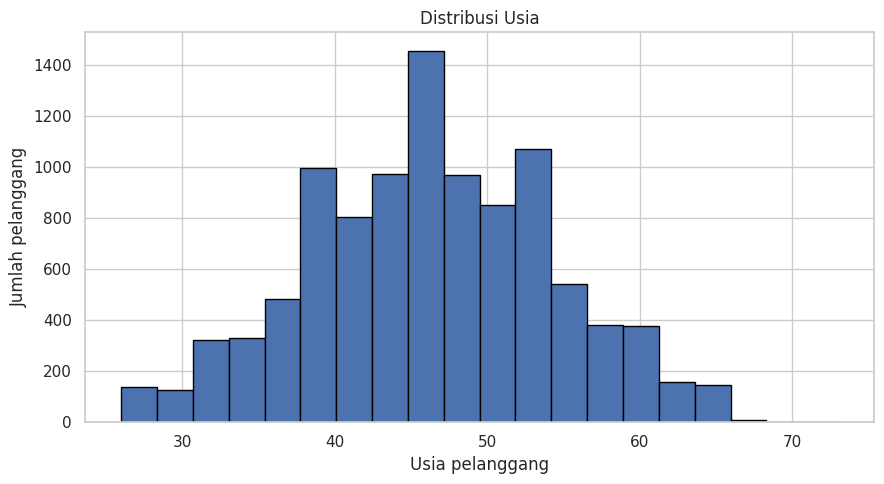

Insight: Usia pelanggang dari 26 ke 73 tahun, Dengan rata rata 46.3 dan nilai tengah 46.0 tahun. Histogram ini menunjukkan di mana populasi pelanggan terkonsentrasi di berbagai kelompok usia.


In [18]:
ages = pd.to_numeric(df["Customer_Age"], errors="coerce").dropna()
#Ngubah bentuk si barisnya jadi data numeric, apabila ada yang tidak bertipe numeric maka dihitung nilai kosong

#pembuat grafiknya
plt.figure(figsize=(9, 5))
plt.hist(ages, bins=20, edgecolor="black")
plt.title("Distribusi Usia")
plt.xlabel("Usia pelanggang")
plt.ylabel("Jumlah pelanggang")
plt.tight_layout()
plt.show()


print(f"Insight: Usia pelanggang dari {ages.min():.0f} ke {ages.max():.0f} tahun, "
      f"Dengan rata rata {ages.mean():.1f} dan nilai tengah {ages.median():.1f} tahun. "
      "Histogram ini menunjukkan di mana populasi pelanggan terkonsentrasi di berbagai kelompok usia.")

### Donut Chart

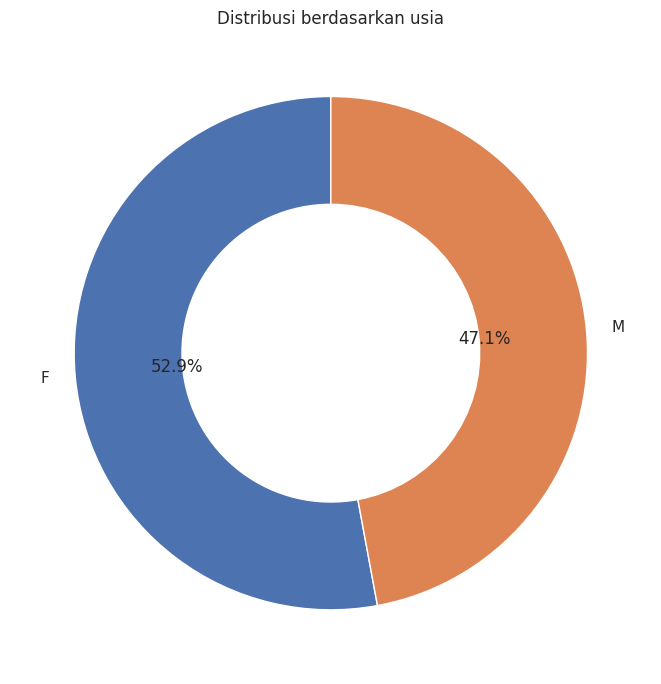

Insight: F: 5,358 customers (52.9%); M: 4,769 customers (47.1%). The chart shows the gender composition of the dataset.


In [17]:
gender_counts = df["Gender"].value_counts()
#Menghitung jumlah gender

plt.figure(figsize=(7, 7))
plt.pie(gender_counts.values, labels=gender_counts.index, autopct="%1.1f%%",
        startangle=90, wedgeprops={"width": 0.42, "edgecolor": "white"})
plt.title("Distribusi berdasarkan usia")
plt.tight_layout()
plt.show()


print("Insight: " + "; ".join(
    f"{g}: {n:,} customers ({n/gender_counts.sum():.1%})"
    for g, n in gender_counts.items()
) + ". Grafiknya menampilkan kompisisi kelamin dari datasetnya.")

### Bar Chart

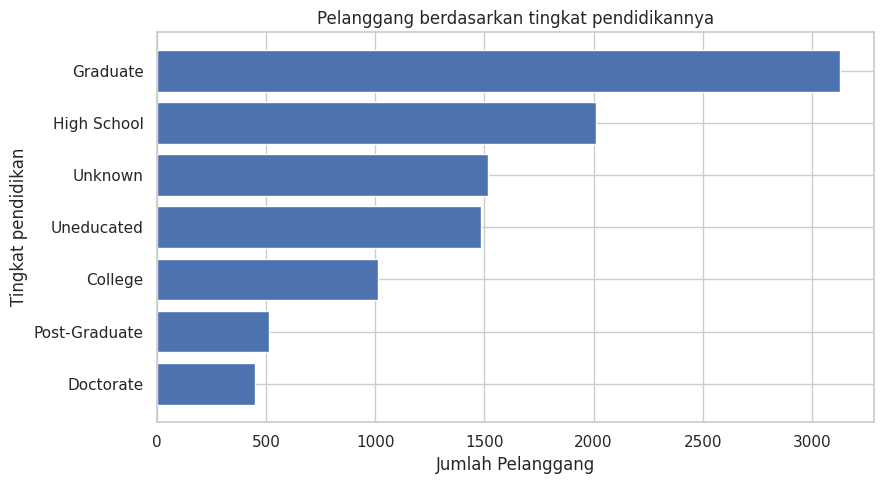

Insight: Kategori pendidikan terbanyak Graduate (3,128 pelanggang, Sedangkan yang terkecil Doctorate (451). Kategori 'Tidak Diketahui' mencerminkan catatan yang tidak memiliki tingkat pendidikan yang ditentukan, jadi, hal itu tidak boleh ditafsirkan sebagai kualifikasi pendidikan yang sesungguhnya.


In [20]:
education_counts = df["Education_Level"].value_counts().sort_values()
plt.figure(figsize=(9, 5))
plt.barh(education_counts.index, education_counts.values)
plt.title("Pelanggang berdasarkan tingkat pendidikannya")
plt.xlabel("Jumlah Pelanggang")
plt.ylabel("Tingkat pendidikan")
plt.tight_layout()
plt.show()

print(f"Insight: Kategori pendidikan terbanyak {education_counts.idxmax()} "
      f"({education_counts.max():,} pelanggang, Sedangkan yang terkecil "
      f"{education_counts.idxmin()} ({education_counts.min():,}). "
      "Kategori 'Tidak Diketahui' mencerminkan catatan yang tidak memiliki tingkat pendidikan yang ditentukan, "
      "jadi, hal itu tidak boleh ditafsirkan sebagai kualifikasi pendidikan yang sesungguhnya.")

### Verical Bar Chart

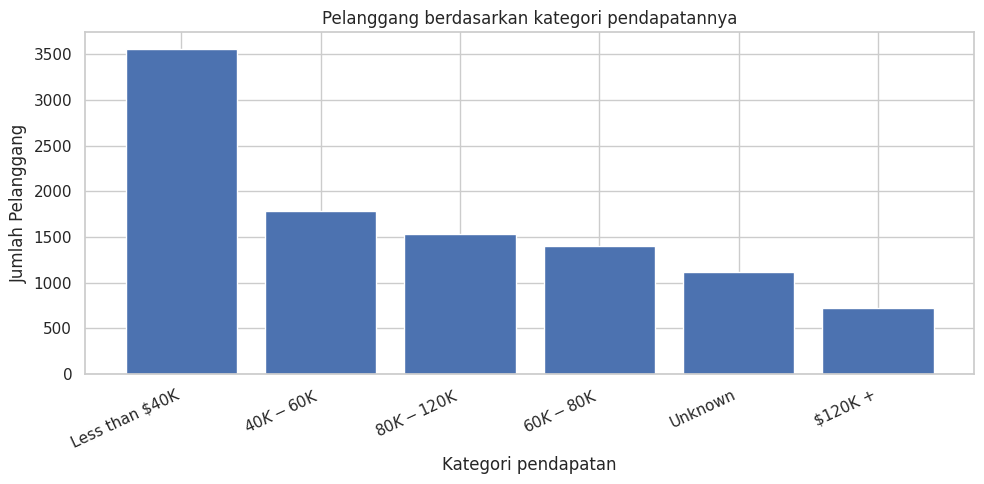

Insight: Kategori paling umum Less than $40K (3,561 pelanggan), dan yang sangat jarang $120K + (727). Kategori 'Tidak Diketahui' merupakan kategori data, bukan golongan pendapatan tertentu.


In [21]:
income_counts = df["Income_Category"].value_counts()
#Menghitung jumlahnya

plt.figure(figsize=(10, 5))
plt.bar(income_counts.index, income_counts.values)
plt.title("Pelanggang berdasarkan kategori pendapatannya")
plt.xlabel("Kategori pendapatan")
plt.ylabel("Jumlah Pelanggang")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

print(f"Insight: Kategori paling umum {income_counts.idxmax()} "
      f"({income_counts.max():,} pelanggan), dan yang sangat jarang "
      f"{income_counts.idxmin()} ({income_counts.min():,}). "
      "Kategori 'Tidak Diketahui' merupakan kategori data, bukan golongan pendapatan tertentu.")

## 2. Grafik Tambahan (Soal 3–5)

### 3. Countplot yang menggabungkan lebih dari satu kolom
Plot ini membandingkan status atrisi berdasarkan jenis kelamin.

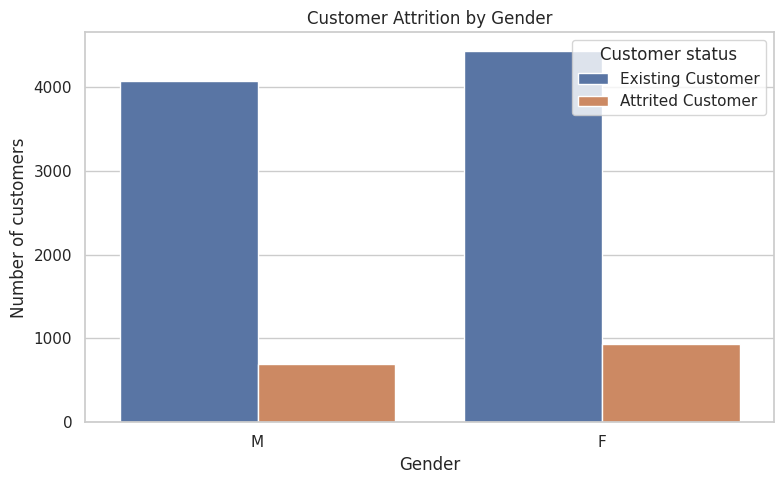

In [29]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Gender", hue="Attrition_Flag")
plt.title("Pelanggan yang keluar berdasarkan jenis kelamin")
plt.xlabel("Jenis kelamin")
plt.ylabel("Jumlah pelanggang")
plt.legend(title="Customer status")
plt.tight_layout()
plt.show()

In [33]:
cross = pd.crosstab(df["Gender"], df["Attrition_Flag"])
rates = (cross["Attrited Customer"] / cross.sum(axis=1) * 100).sort_values(ascending=False)

In [36]:
print("Insight: Countplot tersebut membandingkan jumlah pelanggan yang masih bertahan dan pelanggan yang berhenti (churn) berdasarkan jenis kelamin.")
print("Tingkat pengunduran diri berdasarkan jenis kelamin (%):")
display(rates.round(2).to_frame("attrition_rate_percent"))
print("Interpretasi : Bandingkan persentasenya, bukan sekadar jumlah mentahnya, ")
print("karena kelompok gender mungkin memiliki total ukuran yang berbeda.")
print("Perbedaan yang terlihat dalam grafik ini bersifat deskriptif")
print("tidak membuktikan bahwa gender merupakan penyebab keluarnya individu (atrisi) dari kelompok tersebut.")

Insight: Countplot tersebut membandingkan jumlah pelanggan yang masih bertahan dan pelanggan yang berhenti (churn) berdasarkan jenis kelamin.
Tingkat pengunduran diri berdasarkan jenis kelamin (%):


,attrition_rate_percent
Gender,
F,17.36
M,14.62


Interpretasi : Bandingkan persentasenya, bukan sekadar jumlah mentahnya, 
karena kelompok gender mungkin memiliki total ukuran yang berbeda.
Perbedaan yang terlihat dalam grafik ini bersifat deskriptif
tidak membuktikan bahwa gender merupakan penyebab keluarnya individu (atrisi) dari kelompok tersebut.


### 4. Scatterplot with two numerical columns
The X-axis is `Customer_Age`; the Y-axis is `Total_Trans_Amt`. Color represents attrition status.

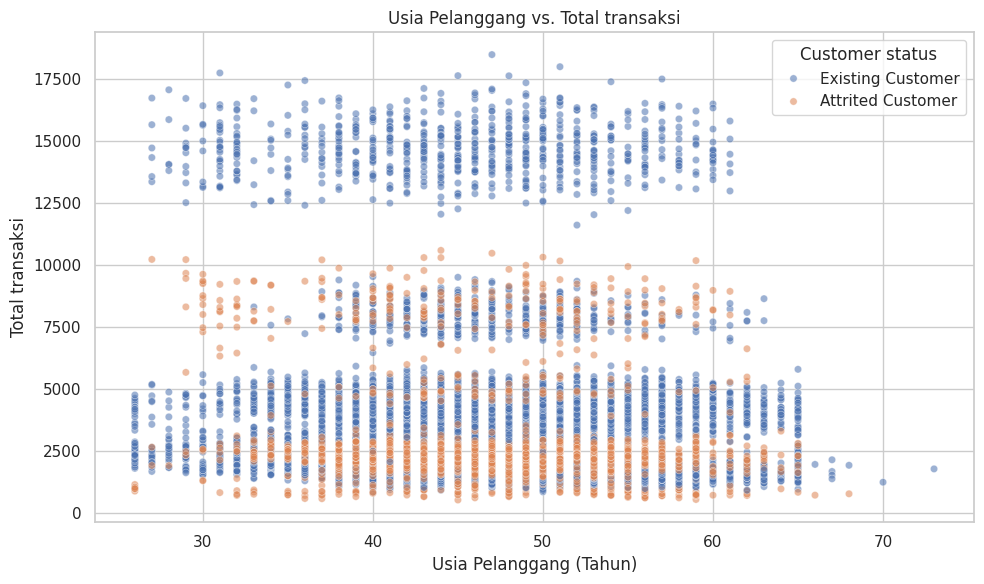

In [37]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Customer_Age", y="Total_Trans_Amt",
                hue="Attrition_Flag", alpha=0.55, s=28)
plt.title("Usia Pelanggang vs. Total transaksi")
plt.xlabel("Usia Pelanggang (Tahun)")
plt.ylabel("Total transaksi")
plt.legend(title="Customer status")
plt.tight_layout()
plt.show()

In [39]:
corr_age_amount = df[["Customer_Age", "Total_Trans_Amt"]].corr().iloc[0, 1]
print(f"Insight: Korelasi Pearson antara usia dan jumlah total transaksi adalah {corr_age_amount:.3f}. "
      "Nilai yang mendekati 0 menunjukkan asosiasi linear yang lemah; nilai yang lebih mendekati -1 atau +1 menunjukkan asosiasi linear negatif atau positif yang lebih kuat. "
      "Diagram pencar juga memperlihatkan sebaran serta kemungkinan adanya pencilan. Korelasi tidak menyiratkan sebab-akibat.")

Insight: Korelasi Pearson antara usia dan jumlah total transaksi adalah -0.046. Nilai yang mendekati 0 menunjukkan asosiasi linear yang lemah; nilai yang lebih mendekati -1 atau +1 menunjukkan asosiasi linear negatif atau positif yang lebih kuat. Diagram pencar juga memperlihatkan sebaran serta kemungkinan adanya pencilan. Korelasi tidak menyiratkan sebab-akibat.


### 5. korelasi berdasarkan heatmapnya
heatmap ini menggunakan variabel numerik pelanggan dan transaksi. `CLIENTNUM` serta dua kolom keluaran Naive Bayes telah dikecualikan.

In [22]:
numeric_cols = [
    "Customer_Age", "Dependent_count", "Months_on_book",
    "Total_Relationship_Count", "Months_Inactive_12_mon",
    "Contacts_Count_12_mon", "Credit_Limit", "Total_Revolving_Bal",
    "Avg_Open_To_Buy", "Total_Amt_Chng_Q4_Q1", "Total_Trans_Amt",
    "Total_Trans_Ct", "Total_Ct_Chng_Q4_Q1", "Avg_Utilization_Ratio"
]

In [23]:
numeric_cols = [c for c in numeric_cols if c in df.columns]
corr = df[numeric_cols].corr(numeric_only=True)

### Grafik Heatmap

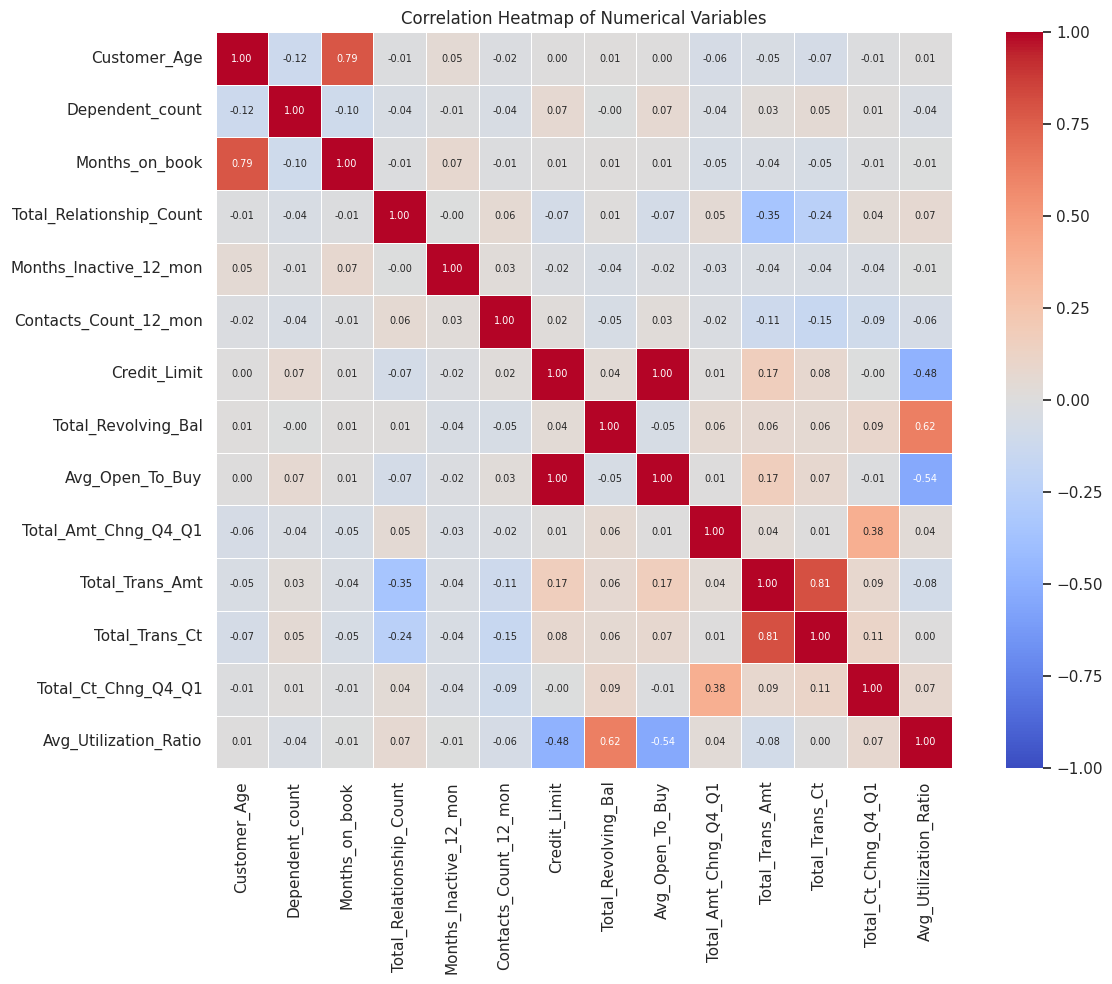

In [24]:
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", square=True, linewidths=0.4,
            annot_kws={"size": 7})
plt.title("Korelasi Heatmap Variabel Numerik")
plt.tight_layout()
plt.show()

In [26]:
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(key=lambda s: s.abs(), ascending=False)

In [28]:
print("Insight: Nilai berwarna merah/positif menunjukkan korelasi linear positif; nilai berwarna biru/negatif menunjukkan korelasi linear negatif. "
      "Nilai mendekati nol menunjukkan korelasi linier yang lemah. Pasangan terkuat dalam dataset ini adalah:")
display(pairs.head(8).rename("correlation").to_frame())
print("Interpretasi: Korelasi yang kuat dapat mencerminkan variabel-variabel yang saling berkaitan atau terhubung secara matematis (sebagai contoh, batas kredit dan kredit yang tersedia). "
      "Hal tersebut tidak menetapkan kausalitas, dan korelasi semata tidak menunjukkan bagaimana suatu variabel memengaruhi atrisi.")

Insight: Nilai berwarna merah/positif menunjukkan korelasi linear positif; nilai berwarna biru/negatif menunjukkan korelasi linear negatif. Nilai mendekati nol menunjukkan korelasi linier yang lemah. Pasangan terkuat dalam dataset ini adalah:


,,correlation
Credit_Limit,Avg_Open_To_Buy,0.995981
Total_Trans_Amt,Total_Trans_Ct,0.807192
Customer_Age,Months_on_book,0.788912
Total_Revolving_Bal,Avg_Utilization_Ratio,0.624022
Avg_Open_To_Buy,Avg_Utilization_Ratio,-0.538808
Credit_Limit,Avg_Utilization_Ratio,-0.482965
Total_Amt_Chng_Q4_Q1,Total_Ct_Chng_Q4_Q1,0.384189
Total_Relationship_Count,Total_Trans_Amt,-0.347229


Interpretasi: Korelasi yang kuat dapat mencerminkan variabel-variabel yang saling berkaitan atau terhubung secara matematis (sebagai contoh, batas kredit dan kredit yang tersedia). Hal tersebut tidak menetapkan kausalitas, dan korelasi semata tidak menunjukkan bagaimana suatu variabel memengaruhi atrisi.
